In [1]:
import os
import numpy as np
import xarray as xr
import rasterio
from rasterio.transform import xy
from rasterio.transform import from_origin

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import ListedColormap, BoundaryNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

from scipy import stats
from scipy.stats import rankdata

from glob import glob

In [2]:
# Step 1: Set path to TIF files
tif_folder = "../output/CAPE"
tif_files = sorted(glob(os.path.join(tif_folder, "*.tif")))

# Step 2: Extract dates from filenames
dates = [os.path.basename(f).replace(".tif", "") for f in tif_files]  # ['DJF 1991', 'MAM 1991', ..., 'SON 2024']

# Step 3: Read one file to get spatial dimensions and transform

with rasterio.open(tif_files[0]) as src:
    height, width = src.height, src.width
    transform = src.transform
    crs = src.crs

    # Generate coordinate values from row and column indices
    row_indices = np.arange(height)
    col_indices = np.arange(width)

    # Get center coordinates
    lon, _ = xy(transform, np.zeros_like(col_indices), col_indices, offset="center")
    _, lat = xy(transform, row_indices, np.zeros_like(row_indices), offset="center")

    lon = np.array(lon)
    lat = np.array(lat)

    if lat[0] > lat[-1]:
        lat = lat[::-1]
        reverse_lat = True
    else:
        reverse_lat = False

# Ensure latitude is in ascending order (as required by xarray)
if lat[0] > lat[-1]:
    lat = lat[::-1]
    reverse_lat = True
else:
    reverse_lat = False

# Step 4: Read all data into a numpy array
data = []
for file in tif_files:
    with rasterio.open(file) as src:
        array = src.read(1)  # Read first band
        if reverse_lat:
            array = np.flipud(array)
        data.append(array)

data = np.stack(data)  # Shape: (137, 401, 521)

# Step 5: Create xarray DataArray
da = xr.DataArray(
    data,
    dims=("date", "latitude", "longitude"),
    coords={
        "date": dates,
        "latitude": lat,
        "longitude": lon
    },
    name="CAPE_anomalies"
)

# Step 6: Save to NetCDF
da.to_netcdf("../output/CAPE_anomalies.nc")

In [2]:
#Significance testing functions
def fdr_correction(p_values_2d, alpha=0.05):
    """Benjamini-Hochberg FDR correction for a 2D field of p-values.
    Returns boolean mask: True = significant after FDR correction."""
    flat = p_values_2d.flatten()
    n = len(flat)
    # Rank ascending (NaNs handled by masking)
    valid = ~np.isnan(flat)
    ranks = np.zeros(n)
    ranks[valid] = rankdata(flat[valid])
    # BH threshold: p <= (rank/n) * alpha
    threshold = (ranks / n) * alpha
    sig_flat = (flat <= threshold) & valid
    return sig_flat.reshape(p_values_2d.shape)


def percentile_significance(observed_da, climatology_da, time_dim, alpha=0.05, fdr=True):
    clim = climatology_da.values
    obs  = observed_da.values
    n    = clim.shape[0]
    p_values = np.sum(np.abs(clim) >= np.abs(obs[np.newaxis, :, :]), axis=0) / n
    if fdr:
        return fdr_correction(p_values, alpha=alpha)
    else:
        return p_values <= alpha


def ttest_significance(observed_da, climatology_da, time_dim, alpha=0.05, fdr=False):
    """
    Two-tailed Student's t-test for a single-year anomaly.
    t = anomaly / std(climatology), df = n-1.
    Land (NaN) cells are explicitly excluded.
    """
    clim = climatology_da.values
    obs  = observed_da.values
    n    = clim.shape[0]
    sigma = np.nanstd(clim, axis=0, ddof=1)
    with np.errstate(invalid='ignore', divide='ignore'):
        t_stat = obs / sigma
    p_values = 2 * stats.t.sf(np.abs(t_stat), df=n - 1)
    land_mask = np.isnan(obs) | (sigma == 0)
    p_values[land_mask] = np.nan
    if fdr:
        return fdr_correction(p_values, alpha=alpha)
    else:
        sig = p_values <= alpha
        sig[land_mask] = False
        return sig


def bootstrap_composite_significance(event_dates, climatology_da, time_dim,
                                     n_bootstrap=1000, alpha=0.05, fdr=False,
                                     random_seed=42):
    """
    Bootstrap significance test for a COMPOSITE of N events.

    Builds a null distribution by drawing N random time steps 1000 times and
    computing their composite mean. p-value = fraction of random composites at
    least as extreme as the observed composite.

    Land cells (NaN in observed composite) are explicitly excluded from the
    output mask to prevent NaN >= NaN comparisons from falsely marking land
    as significant.

    Args:
        event_dates   : list of coordinate values to select
        climatology_da: (time, lat, lon) DataArray of full climatological record
        time_dim      : name of the time dimension ('date' or 'year')
        n_bootstrap   : number of bootstrap samples (default 1000)
        alpha         : significance level (default 0.05)
        fdr           : apply BH-FDR correction (default False — over-conservative
                        for spatially correlated climate fields)
        random_seed   : reproducibility seed

    Returns:
        sig_mask      : (lat, lon) boolean array — True = significant ocean cells only
        obs_composite : (lat, lon) numpy array of observed composite mean
    """
    rng = np.random.default_rng(random_seed)
    n_events = len(event_dates)

    # Observed composite mean
    obs_composite = climatology_da.sel({time_dim: event_dates}).mean(dim=time_dim).values

    # Land mask derived from NaN in the observed composite
    land_mask = np.isnan(obs_composite)

    # Build null distribution
    clim_vals = climatology_da.values  # (n_time, lat, lon)
    n_clim    = clim_vals.shape[0]

    boot_composites = np.stack([
        np.nanmean(clim_vals[rng.integers(0, n_clim, size=n_events)], axis=0)
        for _ in range(n_bootstrap)
    ])  # (n_bootstrap, lat, lon)

    # Two-tailed empirical p-value
    p_values = np.sum(
        np.abs(boot_composites) >= np.abs(obs_composite[np.newaxis]), axis=0
    ) / n_bootstrap

    # Exclude land before thresholding so NaN cells cannot pass
    p_values[land_mask] = np.nan

    if fdr:
        sig_mask = fdr_correction(p_values, alpha=alpha)
    else:
        sig_mask = p_values <= alpha

    sig_mask[land_mask] = False  # belt-and-suspenders: zero out any residual land flags

    return sig_mask, obs_composite

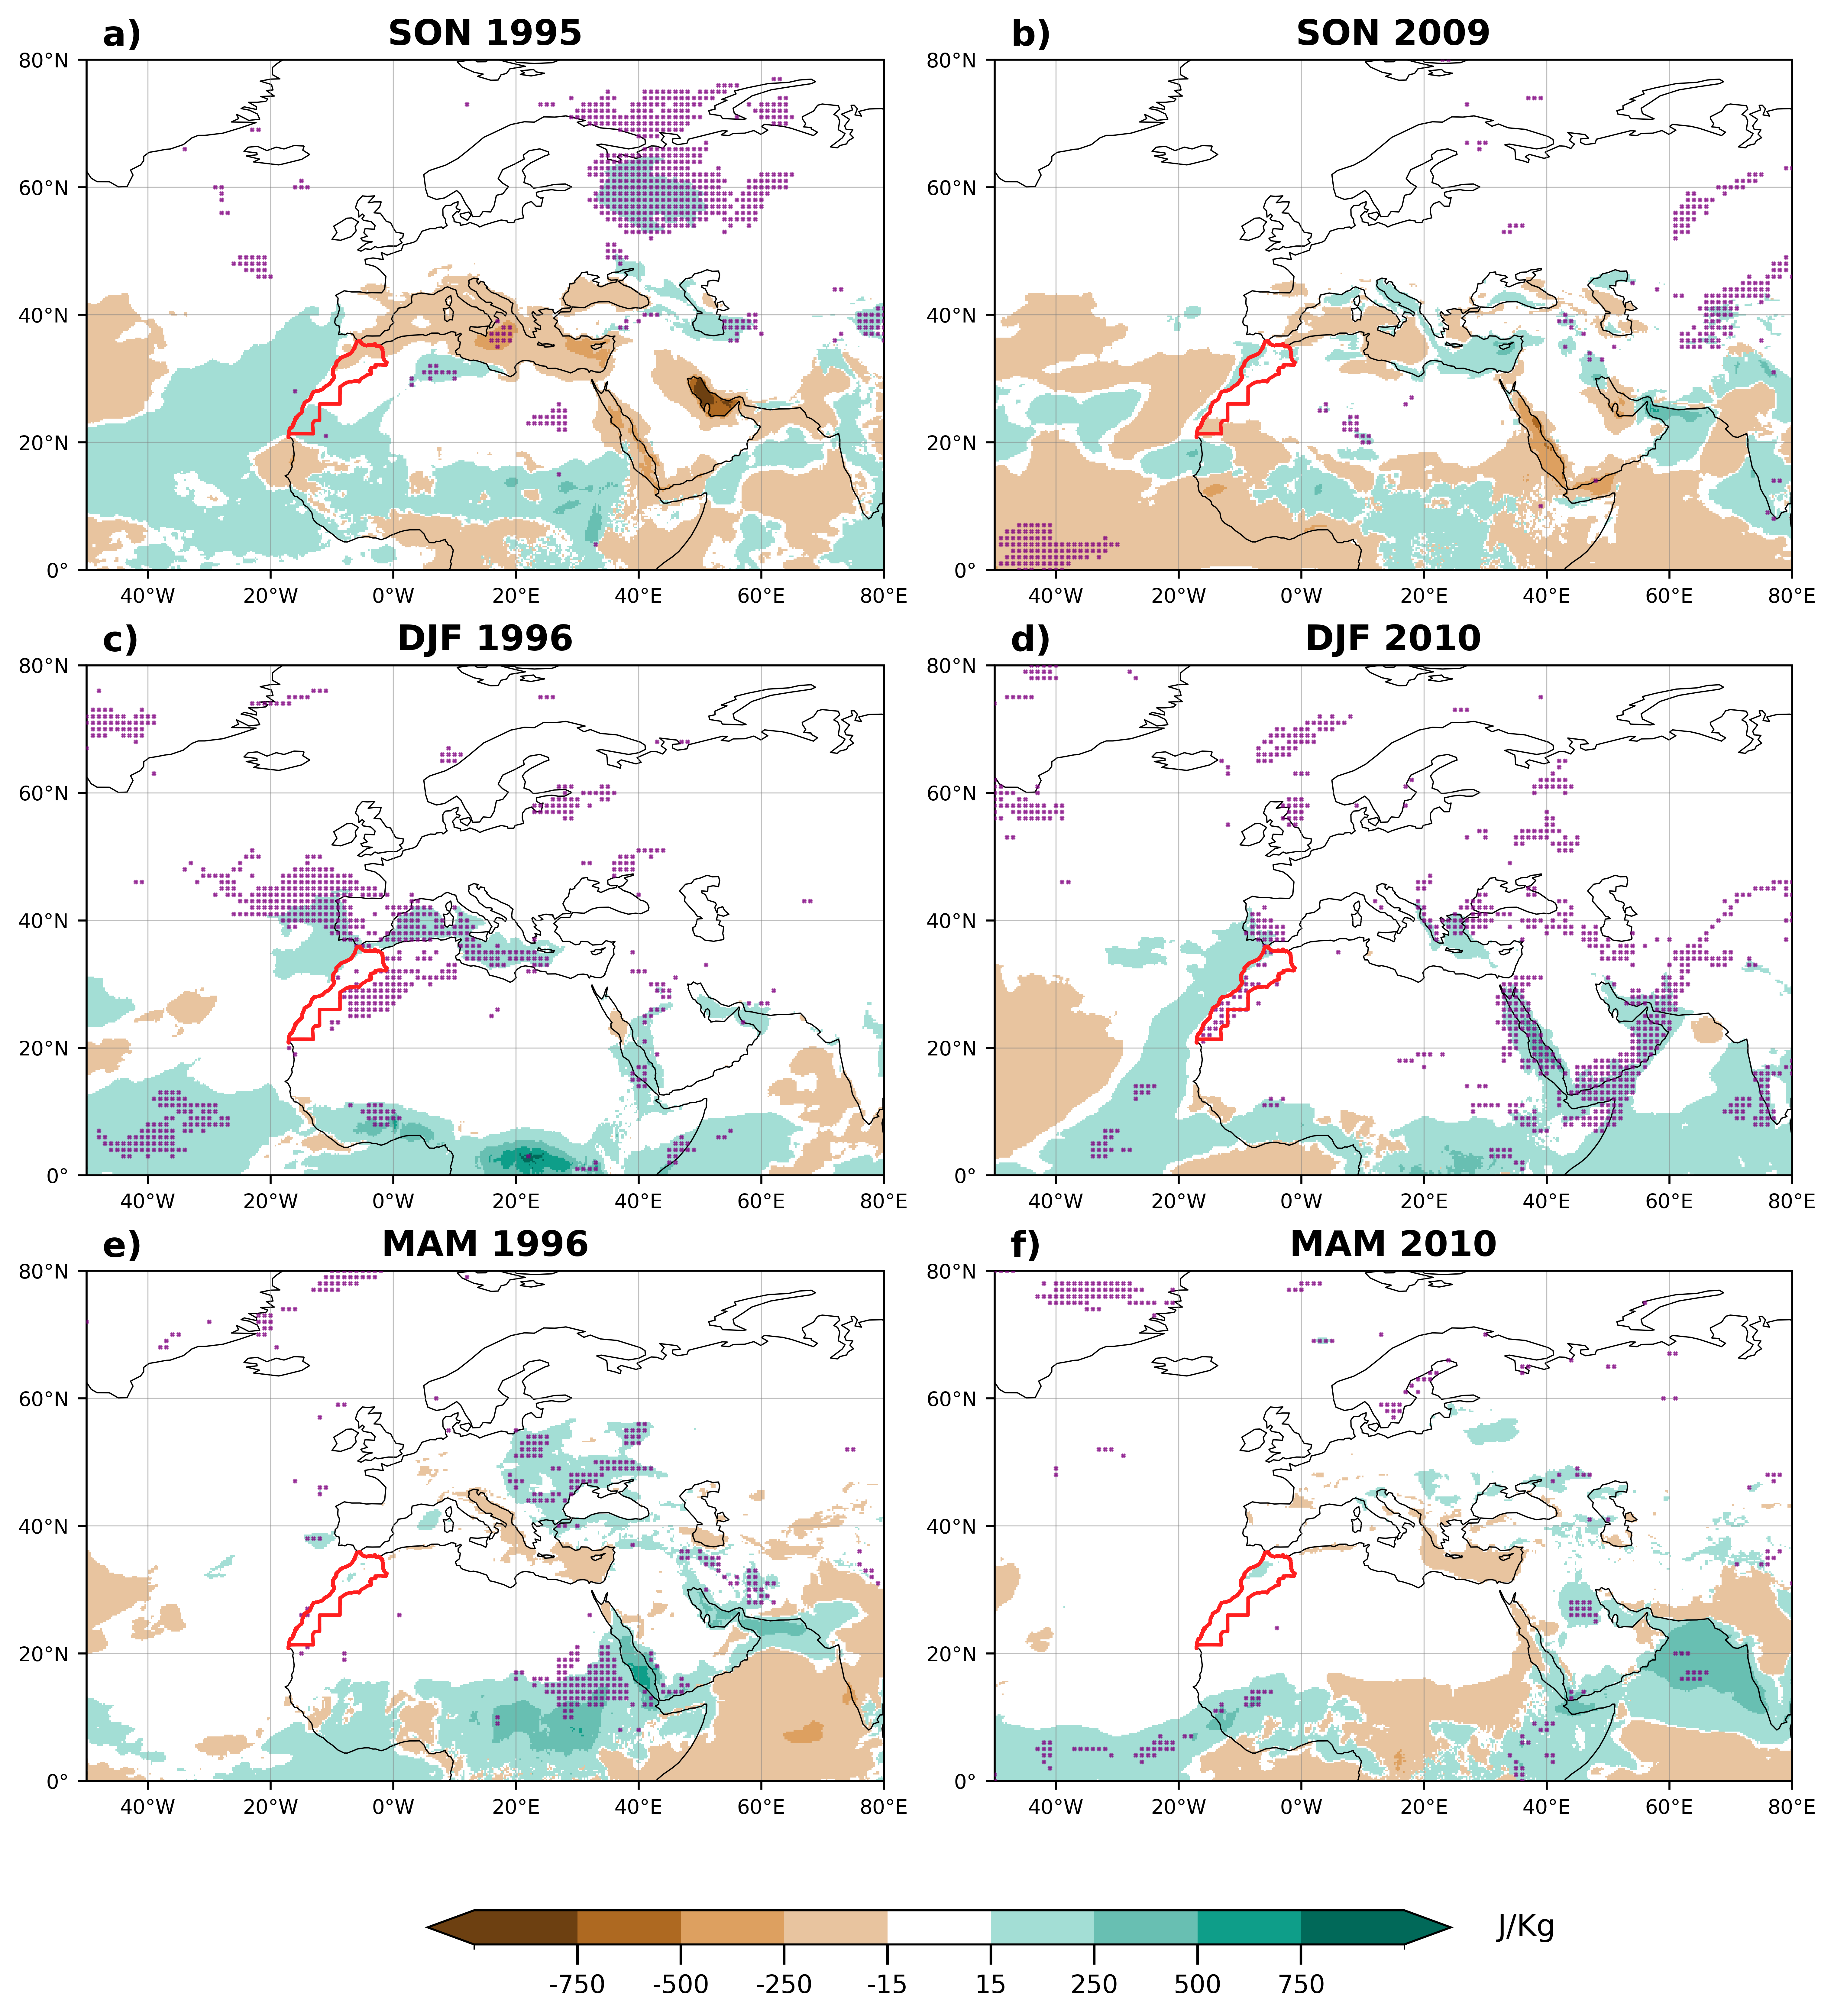

In [3]:
# =============================================================================
# INDIVIDUAL DRY YEARS AND WET YEAR PLOTS for CAPE
# =============================================================================

# --- Load Data ---
anomalies_full = xr.open_dataset("../output/CAPE_anomalies.nc", engine='netcdf4')
anomalies_full = anomalies_full.sel(latitude=slice(0, 80))

# --- SELECTION & LABELING ---
# Define seasonal selections and extract the year
seasons = ['SON 1995', 'SON 2009', 'DJF 1996', 'DJF 2010', 'MAM 1996', 'MAM 2010'] #Main manuscript plot
#seasons = ['SON 2000', 'SON 2022', 'DJF 2001', 'DJF 2023', 'MAM 2001', 'MAM 2023']  #Supplementray material plot
year_label = seasons[1].split()[1]
# Select seasonal data
anomalies = anomalies_full.sel(date=seasons)

# --- COORDINATE FIXES ---
# Shift longitudes to center on Africa ([-180, 180])
def fix_coords(ds):
    ds = ds.assign_coords(longitude=(((ds.longitude + 180) % 360) - 180)).sortby("longitude")
    if ds.latitude[0] > ds.latitude[-1]:
        ds = ds.sortby("latitude")
    return ds

anomalies = fix_coords(anomalies)
anomalies_full = fix_coords(anomalies_full)

# --- SIGNIFICANCE TESTING ---
# Seasonal panels — compare each season against its own seasonal climatology
sig_seasonal = []
for target_date in seasons:
    season_name = target_date.split()[0]  # e.g. 'DJF'
    season_dates = [d for d in anomalies_full.date.values if d.split()[0] == season_name]
    sig = ttest_significance(
        observed_da=anomalies.sel(date=target_date).CAPE_anomalies,
        climatology_da=anomalies_full.sel(date=season_dates).CAPE_anomalies,
        time_dim='date',
        fdr=False
    )
    sig_seasonal.append(sig)

sig_masks = sig_seasonal

# --- DISCRETE CLASS COLORS (QGIS-LIKE BINS) ---
# Bins: < -750, -750:-500, -500:-250, -250:-20, -20:20, 20:250, 250:500, 500:750, > 750
class_colors = [
    '#6d4011',  # strong negative - dark brown
    '#ae6921',  # moderate-strong negative - medium brown
    '#dda060',  # moderate negative - tan
    '#e8c49f',  # light negative - very light brown
    '#FFFFFF',  # near zero - white
    '#a3ded5',  # very light positive - pale green
    '#68bfb2',  # light positive - light green
    '#0e9e89',  # moderate positive - dark green
    '#016959'   # strong positive - very dark green
]
cmap = ListedColormap(class_colors)

all_vals = anomalies.CAPE_anomalies.values
vmin_data = float(np.nanmin(all_vals))
vmax_data = float(np.nanmax(all_vals))

# Ensure open-ended classes always exist even if data range is narrower than +/-750
lower_edge = min(vmin_data, -750.0 - 1e-6)
upper_edge = max(vmax_data, 750.0 + 1e-6)

bounds = [lower_edge, -750, -500, -250, -15, 15, 250, 500, 750, upper_edge]
norm = BoundaryNorm(bounds, cmap.N)

# --- LABELS AND DATA LIST ---
labels = seasons
panel_labels = [f"{chr(97 + i)})" for i in range(len(labels))]
anomaly_list = [anomalies.sel(date=d).to_array().squeeze() for d in anomalies.date.values]

# --- Morocco boundary overlay ---
morocco_shp = "/Users/workad/Workspace/Data-Other/shapfiles/Morocco/Morocco.shp"
if os.path.exists(morocco_shp):
    morocco_geoms = list(shpreader.Reader(morocco_shp).geometries())
else:
    morocco_geoms = []
    print(f"Warning: Morocco shapefile not found at {morocco_shp}")

# --- PLOTTING ---
plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(10, 11),
    subplot_kw={'projection': ccrs.PlateCarree()},
    constrained_layout=True
)
axes = axes.flatten()
lat = anomalies.latitude.values
lon = anomalies.longitude.values

lon_min = float(anomalies.longitude.min())
lon_max = float(anomalies.longitude.max())
lat_min = float(anomalies.latitude.min())
lat_max = float(anomalies.latitude.max())

lon_tick_start = int(np.ceil(lon_min / 20.0) * 20)
lon_tick_end = int(np.floor(lon_max / 20.0) * 20)
lat_tick_start = int(np.ceil(lat_min / 20.0) * 20)
lat_tick_end = int(np.floor(lat_max / 20.0) * 20)

lon_ticks = np.arange(lon_tick_start, lon_tick_end + 1, 20)
lat_ticks = np.arange(lat_tick_start, lat_tick_end + 1, 20)

lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()

for ax, panel_label, label, cape_anomaly, sig_mask in zip(
    axes, panel_labels, labels, anomaly_list, sig_masks
):
    im = ax.imshow(
        cape_anomaly[::-1],
        cmap=cmap,
        norm=norm,
        aspect='auto',
        extent=[
            anomalies.longitude.min(), anomalies.longitude.max(),
            anomalies.latitude.min(), anomalies.latitude.max()
        ],
        transform=ccrs.PlateCarree()
    )

    # --- Significance stippling ---
    # Thin out the marker by subsampling every N-th point to avoid overplotting
    stride = 4
    lon_2d, lat_2d = np.meshgrid(lon[::stride], lat[::stride])
    sig_sub = sig_mask[::stride, ::stride]
    ax.scatter(
        lon_2d[sig_sub], lat_2d[sig_sub],
        marker='X', linewidths=0.5,
        s=2, color='purple', alpha=0.6,
        transform=ccrs.PlateCarree(), zorder=3.6
    )

    # --- OPTION B: Contour boundary around significant regions ---
    #ax.contour(
    #    lon, lat, sig_mask.astype(float),
    #    levels=[0.5], colors='black', linewidths=0.5,
    #   transform=ccrs.PlateCarree(), zorder=3
    #)
    
    # Add map features
    ax.coastlines(resolution='110m', linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='white')

    # Highlight Morocco in bright red using user-provided shapefile
    if morocco_geoms:
        ax.add_geometries(
            morocco_geoms,
            crs=ccrs.PlateCarree(),
            facecolor='none',
            edgecolor='#ff1f1f',
            linewidth=1.4,
            zorder=6
        )

    # Panel label (a, b, c...) in the top-left corner
    ax.text(
        0.02,
        1.08,
        panel_label,
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=14,
        fontweight='bold',
        color='black',
        zorder=5
    )

    ax.set_title(label, fontsize=14, fontweight='bold')

    # Axis ticks/labels every 20°
    ax.set_xticks(lon_ticks, crs=ccrs.PlateCarree())
    ax.set_yticks(lat_ticks, crs=ccrs.PlateCarree())
    ax.xaxis.set_major_formatter(lon_formatter)
    ax.yaxis.set_major_formatter(lat_formatter)
    ax.tick_params(labelsize=8)

    # Gridlines every 20°
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=False,
        linewidth=0.4,
        color='gray',
        alpha=0.5,
        linestyle='-'
    )
    gl.xlocator = mticker.FixedLocator(lon_ticks)
    gl.ylocator = mticker.FixedLocator(lat_ticks)

# --- COLORBAR (DISCRETE CLASSES) ---
cbar = fig.colorbar(
    im,
    ax=axes,
    orientation='horizontal',
    fraction=0.07,
    pad=0.05,
    aspect=30,
    shrink=0.6,
    boundaries=bounds,
    extend='both'
)

tick_positions = bounds[1:-1]
tick_labels = ['-750', '-500', '-250', '-15', '15', '250', '500', '750']

cbar.set_ticks(tick_positions)
cbar.set_ticklabels(tick_labels)
cbar.ax.text(1.10, 0.5, 'J/Kg', transform=cbar.ax.transAxes,
             fontsize=12, va='center', ha='left')
cbar.ax.tick_params(labelsize=10, direction='out', length=8, width=1)
cbar.outline.set_linewidth(0.8)

# --- EXPORT / DISPLAY ---
plt.savefig("CAPEAnomalies_Supp2.png", dpi=600) 
#plt.savefig("CAPEAnomalies_Main.png", dpi=600)
plt.show()

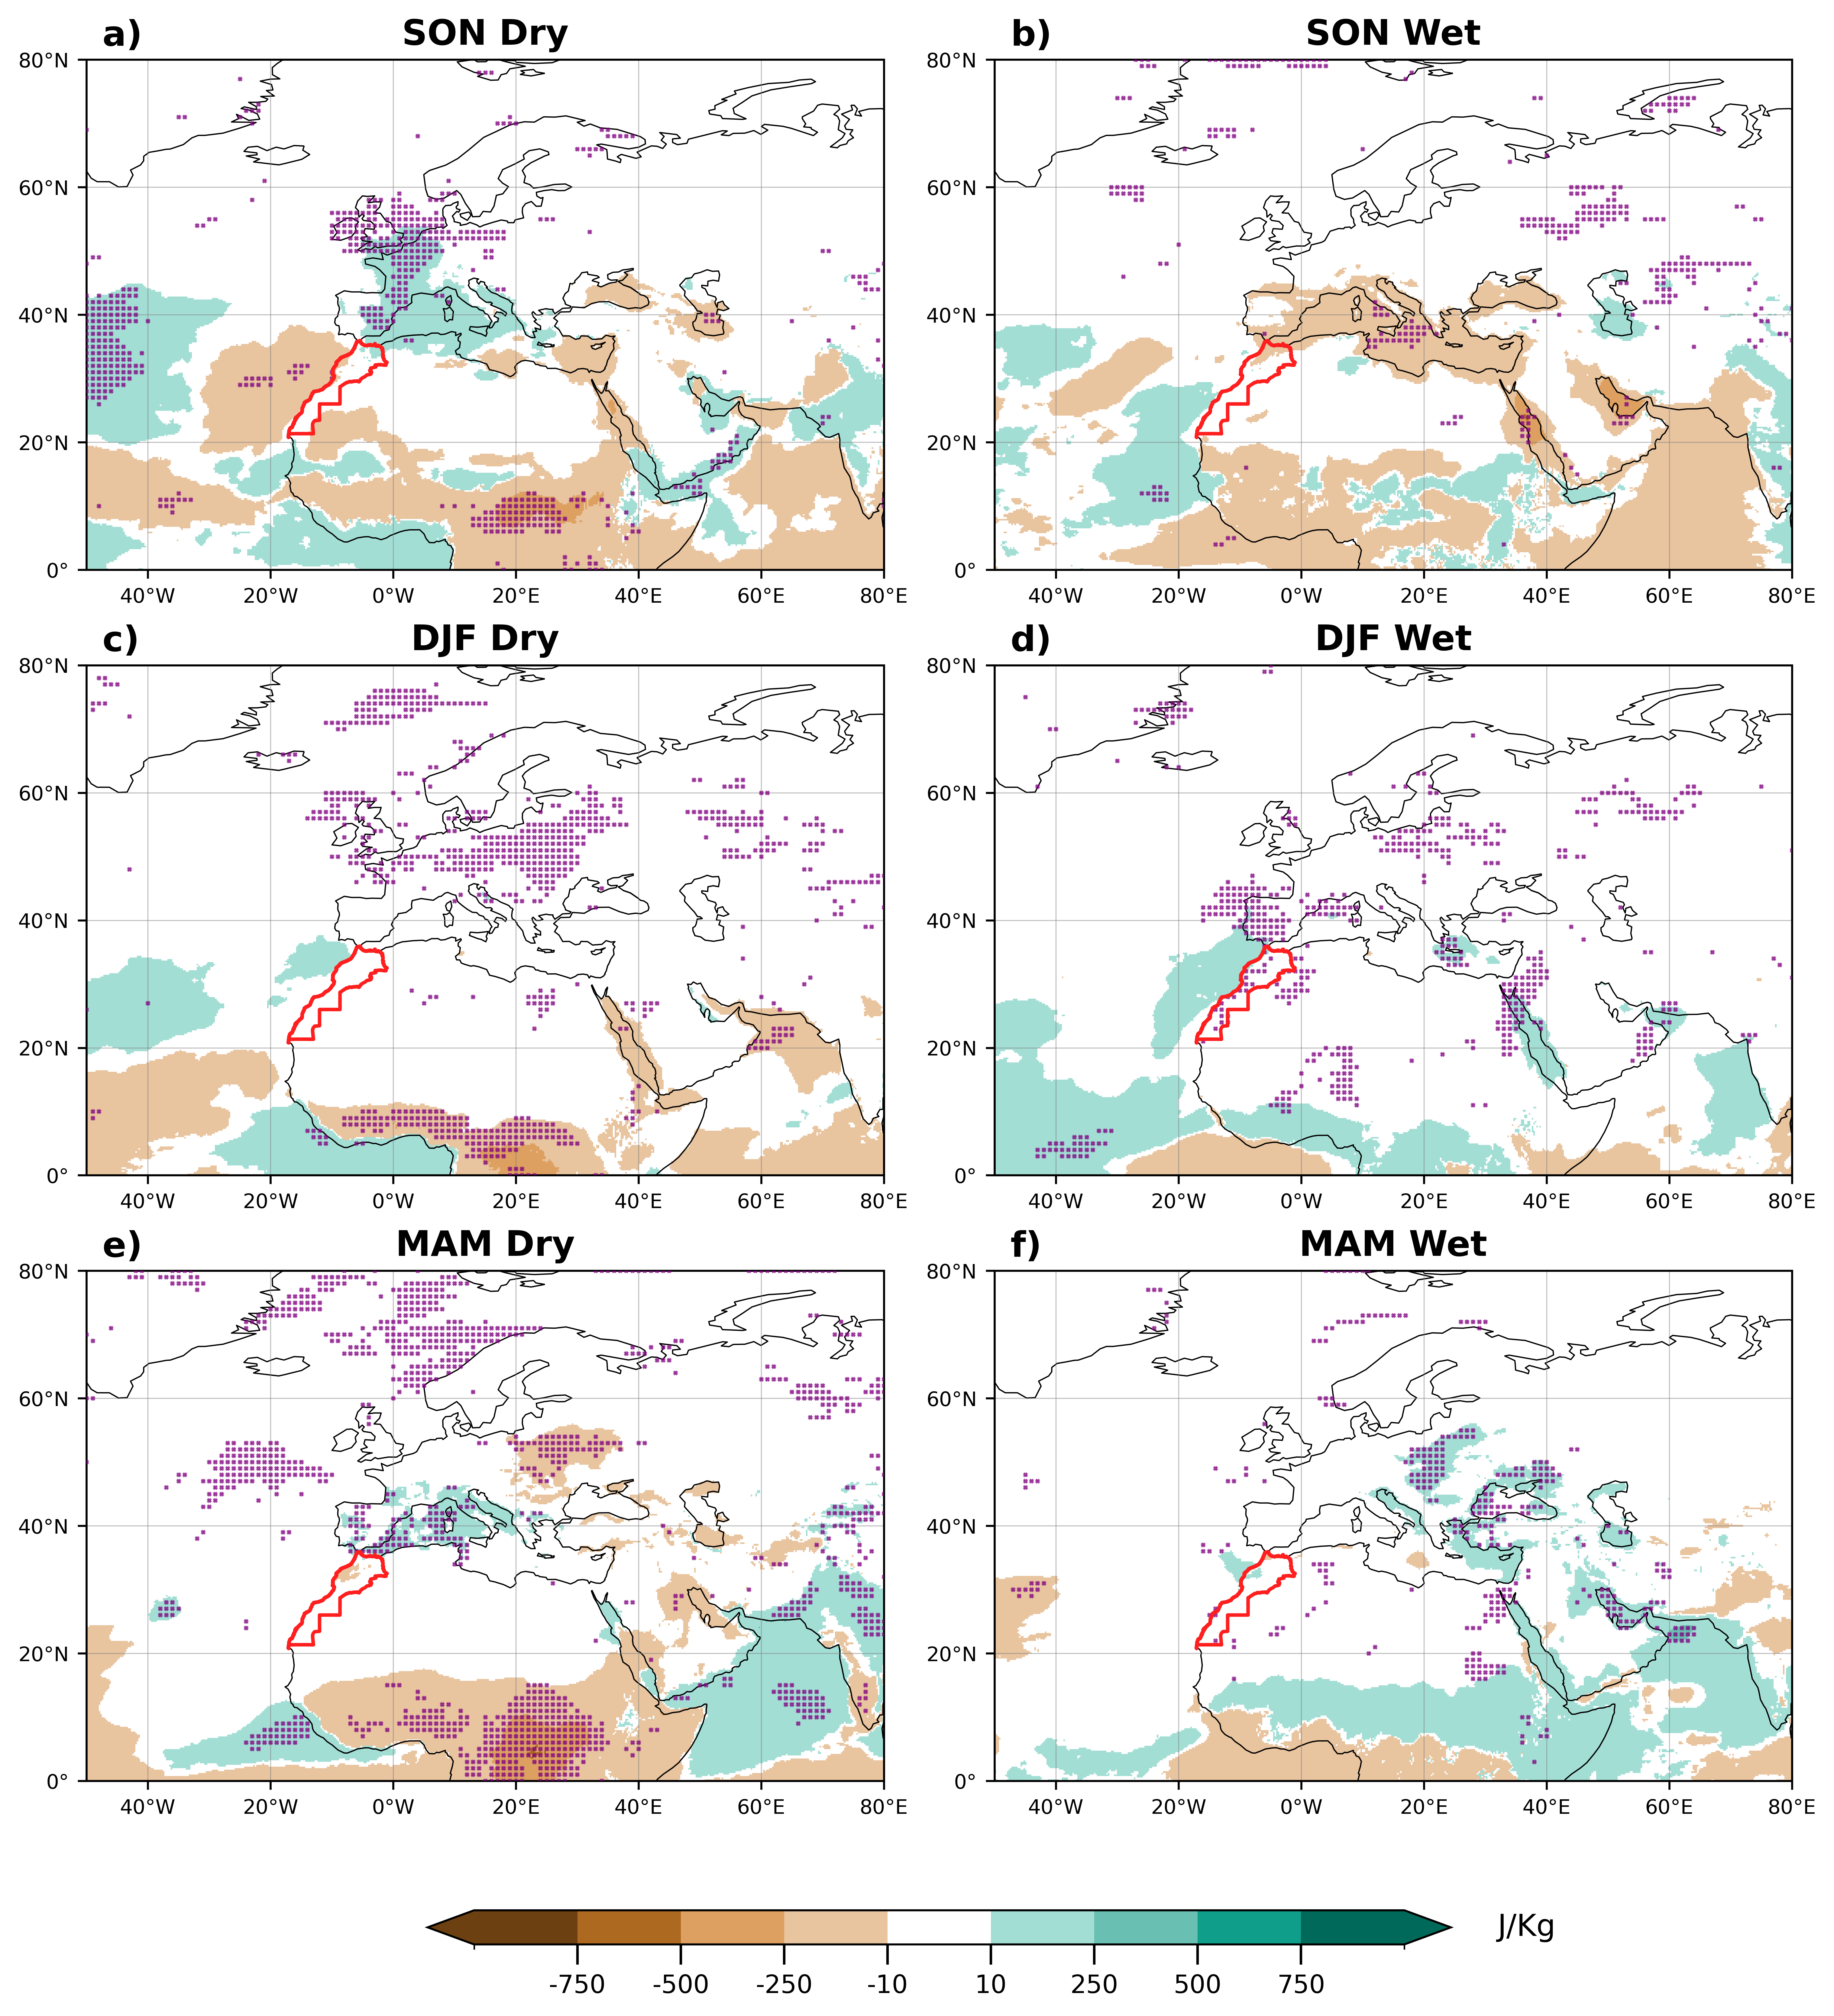

In [7]:

# =============================================================================
# COMPOSITE ANALYSIS — DRY AND WET YEARS for CAPE
# =============================================================================

# --- CONFIGURATION ---
dry_years = [2000, 2001, 2020, 2022, 2023]
wet_years = [1996, 1997, 2010, 2014, 2018]

# Convention: for year Y, use SON(Y-1), DJF(Y), MAM(Y)
# — matches the North African wet season (Oct–May)
dry_son = [f'SON {y - 1}' for y in dry_years]
dry_djf = [f'DJF {y}'     for y in dry_years]
dry_mam = [f'MAM {y}'     for y in dry_years]

wet_son = [f'SON {y - 1}' for y in wet_years]
wet_djf = [f'DJF {y}'     for y in wet_years]
wet_mam = [f'MAM {y}'     for y in wet_years]

# --- LOAD DATA ---
anomalies_full = xr.open_dataset("../output/CAPE_anomalies.nc", engine='netcdf4')
anomalies_full = anomalies_full.sel(latitude=slice(0, 80))

# --- COORDINATE FIXES ---
def fix_coords(ds):
    ds = ds.assign_coords(longitude=(((ds.longitude + 180) % 360) - 180)).sortby("longitude")
    if ds.latitude[0] > ds.latitude[-1]:
        ds = ds.sortby("latitude")
    return ds

anomalies_full = fix_coords(anomalies_full)

# --- STEP 1: COMPUTE SEASONAL COMPOSITE MEANS ---
cape_var = 'CAPE_anomalies'

comp_dry_son = anomalies_full[cape_var].sel(date=dry_son).mean(dim='date')
comp_dry_djf = anomalies_full[cape_var].sel(date=dry_djf).mean(dim='date')
comp_dry_mam = anomalies_full[cape_var].sel(date=dry_mam).mean(dim='date')

comp_wet_son = anomalies_full[cape_var].sel(date=wet_son).mean(dim='date')
comp_wet_djf = anomalies_full[cape_var].sel(date=wet_djf).mean(dim='date')
comp_wet_mam = anomalies_full[cape_var].sel(date=wet_mam).mean(dim='date')

# Layout order: (SON dry, SON wet) | (DJF dry, DJF wet) | (MAM dry, MAM wet)
composite_data = [
    comp_dry_son, comp_wet_son,
    comp_dry_djf, comp_wet_djf,
    comp_dry_mam, comp_wet_mam,
]
composite_labels = [
    'SON Dry', 'SON Wet',
    'DJF Dry', 'DJF Wet',
    'MAM Dry', 'MAM Wet',
]
panel_labels = [f"{chr(97 + i)})" for i in range(6)]

# Season-matched climatology date lists (GPH format: 'SON YYYY', 'DJF YYYY', 'MAM YYYY')
all_son_dates = [d for d in anomalies_full.date.values if d.split()[0] == 'SON']
all_djf_dates = [d for d in anomalies_full.date.values if d.split()[0] == 'DJF']
all_mam_dates = [d for d in anomalies_full.date.values if d.split()[0] == 'MAM']

# --- STEP 2: SIGNIFICANCE TESTING ---

# ── OPTION 1: t-test (composite version) ─────────────────────────────────────
# H0: composite mean = 0; t = mean(events) / (σ_climatology / √N)
# df = N - 1 = 4  →  t_crit ≈ ±2.78  (very conservative with N=5)
#def ttest_composite_significance(event_das, climatology_da, time_dim, alpha=0.05):
#    """
#    Composite t-test: tests whether the mean of N event anomalies is significantly
#    different from zero, normalized by the standard error of the climatological mean.
#
#    t = mean(events) / (std(climatology) / sqrt(N))
#    df = N - 1
#
#    This is more appropriate than the single-year t-test for composites because
#    it uses df = N-1 (event count), not df = n_clim-1.
#    """
#    N     = len(event_das) if hasattr(event_das, '__len__') else event_das.shape[0]
#    clim  = climatology_da.values
#    obs   = np.stack([da.values for da in event_das], axis=0)  # (N, lat, lon)
#
#    comp_mean = np.nanmean(obs, axis=0)
#    sigma     = np.nanstd(clim, axis=0, ddof=1)   # climatological std
#
#    with np.errstate(invalid='ignore', divide='ignore'):
#        t_stat = comp_mean / (sigma / np.sqrt(N))
#
#    p_values  = 2 * stats.t.sf(np.abs(t_stat), df=N - 1)
#
#    land_mask = np.isnan(comp_mean) | (sigma == 0)
#    p_values[land_mask] = np.nan
#
#    sig = p_values <= alpha
#    sig[land_mask] = False
#    return sig

#sig_ann_ttest = ttest_composite_significance(
#    [an_anomalies_full.sst_anomaly.sel(year=y) for y in dry_years],
#    an_anomalies_full.sst_anomaly, time_dim='year'
#)
#
#sig_aut_ttest = ttest_composite_significance(
#    [anomalies_full.sst_anomaly.sel(date=d) for d in dry_autumn],
#    anomalies_full.sst_anomaly.sel(date=all_autumn_dates), time_dim='date'
#)
#sig_win_ttest = ttest_composite_significance(
#    [anomalies_full.sst_anomaly.sel(date=d) for d in dry_winter],
#    anomalies_full.sst_anomaly.sel(date=all_winter_dates), time_dim='date'
#)
#sig_spr_ttest = ttest_composite_significance(
#    [anomalies_full.sst_anomaly.sel(date=d) for d in dry_spring],
#    anomalies_full.sst_anomaly.sel(date=all_spring_dates), time_dim='date'
#)
#
#sig_masks_ttest = [sig_ann_ttest, sig_aut_ttest, sig_win_ttest, sig_spr_ttest]

# ── OPTION 2: Bootstrap (recommended for composites) ─────────────────────────
# Null: draw N random years 1000 times, compute composite each time.
# p = fraction of random composites as extreme as the observed composite.
# No normality assumption; directly simulates the null hypothesis.

sig_dry_son, _ = bootstrap_composite_significance(
    dry_son, anomalies_full[cape_var].sel(date=all_son_dates), time_dim='date',
    n_bootstrap=1000, fdr=False
)
sig_dry_djf, _ = bootstrap_composite_significance(
    dry_djf, anomalies_full[cape_var].sel(date=all_djf_dates), time_dim='date',
    n_bootstrap=1000, fdr=False
)
sig_dry_mam, _ = bootstrap_composite_significance(
    dry_mam, anomalies_full[cape_var].sel(date=all_mam_dates), time_dim='date',
    n_bootstrap=1000, fdr=False
)
sig_wet_son, _ = bootstrap_composite_significance(
    wet_son, anomalies_full[cape_var].sel(date=all_son_dates), time_dim='date',
    n_bootstrap=1000, fdr=False
)
sig_wet_djf, _ = bootstrap_composite_significance(
    wet_djf, anomalies_full[cape_var].sel(date=all_djf_dates), time_dim='date',
    n_bootstrap=1000, fdr=False
)
sig_wet_mam, _ = bootstrap_composite_significance(
    wet_mam, anomalies_full[cape_var].sel(date=all_mam_dates), time_dim='date',
    n_bootstrap=1000, fdr=False
)

sig_masks = [
    sig_dry_son, sig_wet_son,
    sig_dry_djf, sig_wet_djf,
    sig_dry_mam, sig_wet_mam,
]

# --- DISCRETE CLASS COLORS (QGIS-LIKE BINS) ---
# Bins: < -750, -750:-500, -500:-250, -250:-20, -20:20, 20:250, 250:500, 500:750, > 750
class_colors = [
    '#6d4011',  # strong negative - dark brown
    '#ae6921',  # moderate-strong negative - medium brown
    '#dda060',  # moderate negative - tan
    '#e8c49f',  # light negative - very light brown
    '#FFFFFF',  # near zero - white
    '#a3ded5',  # very light positive - pale green
    '#68bfb2',  # light positive - light green
    '#0e9e89',  # moderate positive - dark green
    '#016959'   # strong positive - very dark green
]
cmap = ListedColormap(class_colors)

all_vals = anomalies_full.CAPE_anomalies.values
vmin_data = float(np.nanmin(all_vals))
vmax_data = float(np.nanmax(all_vals))

# Ensure open-ended classes always exist even if data range is narrower than +/-750
lower_edge = min(vmin_data, -750.0 - 1e-6)
upper_edge = max(vmax_data, 750.0 + 1e-6)

bounds = [lower_edge, -750, -500, -250, -10, 10, 250, 500, 750, upper_edge]
norm = BoundaryNorm(bounds, cmap.N)

# --- Morocco boundary overlay ---
morocco_shp = "/Users/workad/Workspace/Data-Other/shapfiles/Morocco/Morocco.shp"
if os.path.exists(morocco_shp):
    morocco_geoms = list(shpreader.Reader(morocco_shp).geometries())
else:
    morocco_geoms = []
    print(f"Warning: Morocco shapefile not found at {morocco_shp}")

# --- Wind arrow settings ---
wind_defaults = {
    "stride": 24,
    "width": 0.004,
    "key_x": 0.82,
    "key_y": 1.04,
    "target_max_arrow_length": 0.07,
    "reference_arrow_length": 0.05,
    "use_min_arrow_length": False,
    "min_arrow_length": 0.015
}

# --- STEP 4: PLOT ---
lat     = anomalies_full.latitude.values
lon     = anomalies_full.longitude.values

lon_min = float(anomalies_full.longitude.min())
lon_max = float(anomalies_full.longitude.max())
lat_min = float(anomalies_full.latitude.min())
lat_max = float(anomalies_full.latitude.max())

lon_tick_start = int(np.ceil(lon_min  / 20.0) * 20)
lon_tick_end   = int(np.floor(lon_max / 20.0) * 20)
lat_tick_start = int(np.ceil(lat_min  / 20.0) * 20)
lat_tick_end   = int(np.floor(lat_max / 20.0) * 20)
lon_ticks = np.arange(lon_tick_start, lon_tick_end + 1, 20)
lat_ticks = np.arange(lat_tick_start, lat_tick_end + 1, 20)

lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter  = LatitudeFormatter()

plt.rcParams['figure.dpi'] = 600
plt.rcParams['savefig.dpi'] = 600
fig, axes = plt.subplots(
    nrows=3, ncols=2,
    figsize=(10, 11),
    subplot_kw={'projection': ccrs.PlateCarree()},
    constrained_layout=True
)
axes = axes.flatten()

for ax, panel_label, label, comp, sig_mask in zip(
    axes, panel_labels, composite_labels, composite_data,
    sig_masks
):
    im = ax.imshow(
        comp.values[::-1],
        cmap=cmap, norm=norm,
        aspect='auto',
        extent=[lon.min(), lon.max(), lat.min(), lat.max()],
        transform=ccrs.PlateCarree()
    )
    # --- Significance stippling ---
    stride = 4
    lon_2d, lat_2d = np.meshgrid(lon[::stride], lat[::stride])
    sig_sub = sig_mask[::stride, ::stride]
    ax.scatter(
        lon_2d[sig_sub], lat_2d[sig_sub],
        marker='X', linewidths=0.5,
        s=2, color='purple', alpha=0.6,
        transform=ccrs.PlateCarree(), zorder=3.6
    )

    # Add map features
    ax.coastlines(resolution='110m', linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='white')

    # Morocco boundary
    if morocco_geoms:
        ax.add_geometries(
            morocco_geoms, crs=ccrs.PlateCarree(),
            facecolor='none', edgecolor='#ff1f1f', linewidth=1.4, zorder=6
        )

    # Panel label (a, b, c...) top-left
    ax.text(
        0.02, 1.08, panel_label,
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=14, fontweight='bold', color='black', zorder=5
    )

    ax.set_title(label, fontsize=14, fontweight='bold')

    # Axis ticks/labels every 20°
    ax.set_xticks(lon_ticks, crs=ccrs.PlateCarree())
    ax.set_yticks(lat_ticks, crs=ccrs.PlateCarree())
    ax.xaxis.set_major_formatter(lon_formatter)
    ax.yaxis.set_major_formatter(lat_formatter)
    ax.tick_params(labelsize=8)

    # Gridlines every 20°
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(), draw_labels=False,
        linewidth=0.4, color='gray', alpha=0.5, linestyle='-'
    )
    gl.xlocator = mticker.FixedLocator(lon_ticks)
    gl.ylocator = mticker.FixedLocator(lat_ticks)

# --- COLORBAR (DISCRETE CLASSES) ---
cbar = fig.colorbar(
    im,
    ax=axes,
    orientation='horizontal',
    fraction=0.07,
    pad=0.05,
    aspect=30,
    shrink=0.6,
    boundaries=bounds,
    extend='both'
)

tick_positions = bounds[1:-1]
tick_labels = ['-750', '-500', '-250', '-10', '10', '250', '500', '750']

cbar.set_ticks(tick_positions)
cbar.set_ticklabels(tick_labels)
cbar.ax.text(1.10, 0.5, 'J/Kg', transform=cbar.ax.transAxes,
             fontsize=12, va='center', ha='left')
cbar.ax.tick_params(labelsize=10, direction='out', length=8, width=1)
cbar.outline.set_linewidth(0.8)

# --- EXPORT / DISPLAY ---
plt.savefig("CAPEAnomalies_Composite.png", dpi=600)
plt.show()